In [1]:
2+2

4

In [2]:
import os
import json
from pathlib import Path

import random
import pandas as pd
import numpy as np
# import torch
import seaborn as sns
import matplotlib.pyplot as plt
# import cv2
# from tqdm import tqdm


import ast
import re


# EK100

* **What is:** Massive egocentric (first-person) video dataset. People cook in own kitchens. Wear head-mounted camera. Unscripted, real life.
* **Scale:** 100 hours video, 700 kitchens, 90K+ action segments.
* **Target:** Action Recognition / Action Detection. Predict **Verb + Noun** (e.g., *cut* + *tomato* = action *cut tomato*).
* **Labels:** ~97 Verbs, ~300 Nouns, ~4,000 Action combinations. High class imbalance (few frequent, many rare).

Notes:
- verb column and verb_class columns are different. verb_class is superset and the mapping can be found in EPIC_100_verb_classes.csv
- Same as above for noun classes
* **Egocentric motion:** Camera moves fast with head. Heavy blur, sudden view changes.
* **Long-tail distribution:** Few actions happen constantly; most actions happen rarely. Need specialized losses or sampling.
* **Train/Val Splits:** Split by kitchen/participant (unseen kitchens in validation/test). Models must generalize to new environments, not just learn kitchen background.
* **Pre-extracted Features:** Downloading raw video takes terabytes. Most researchers use pre-extracted features (SlowFast, TSN, ViT) provided by benchmark maintainers.


Analysis:
- Train / val set counts and percentage splits
- Top15/Bottom15 verbs
- Distribution of classes in the train/val sets

Noun analysis: 
- Using verb_category (97 unique verb classes)
- I will use noun_category
- Conditional probabilities P(Noun | Verb) (what nouns dominate a given action)
- Conditional Probabilities P(Verb | Noun) (what verbs dominate a given noun)
- Co-occurence matrix of top verb_classes and noun_classes (Plot)

In [18]:
ek100_path = Path("/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/epic_kitchens_100_annotations")
df_train = pd.read_csv(ek100_path / "EPIC_100_train.csv")
df_val = pd.read_csv(ek100_path / "EPIC_100_validation.csv")

# Add split column and concatenate
df_train['split'] = 'train'
df_val['split'] = 'val'
df = pd.concat([df_train, df_val], ignore_index=True)

print(df.shape)
df.head(2)

(76885, 16)


,narration_id,participant_id,video_id,narration_timestamp,start_timestamp,stop_timestamp,start_frame,stop_frame,narration,verb,verb_class,noun,noun_class,all_nouns,all_noun_classes,split
0,P01_01_0,P01,P01_01,00:00:01.089,00:00:00.14,00:00:03.37,8,202,open door,open,3,door,3,['door'],[3],train
1,P01_01_1,P01,P01_01,00:00:02.629,00:00:04.37,00:00:06.17,262,370,turn on light,turn-on,6,light,114,['light'],[114],train


#### video file names are like this

videos = [
"P01_01_1.mp4", 
"P01_01_107.mp4", 
"P01_01_118.mp4", 
"P01_01_12.mp4", 
"P01_01_190.mp4",
]

In [19]:
print(f"Total Train Samples: {len(df_train):,}")
print(f"Total Val Samples:   {len(df_val):,}")
df.split.value_counts(1)*100

Total Train Samples: 67,217
Total Val Samples:   9,668


split
train    87.425376
val      12.574624
Name: proportion, dtype: float64

In [20]:
# Load verb ID to verb name mapping
verbs_df = pd.read_csv(ek100_path / "EPIC_100_verb_classes.csv", header=0, usecols=[0, 1])
verb_map = dict(zip(verbs_df['id'], verbs_df['key']))

nouns_df = pd.read_csv(ek100_path / "EPIC_100_noun_classes.csv", header=0, usecols=[0, 1])
noun_map = dict(zip(nouns_df['id'], nouns_df['key']))

In [21]:
df['verb_category'] = df['verb_class'].map(verb_map)
df['noun_category'] = df['noun_class'].map(noun_map)
df.head(10)

,narration_id,participant_id,video_id,narration_timestamp,start_timestamp,stop_timestamp,start_frame,stop_frame,narration,verb,verb_class,noun,noun_class,all_nouns,all_noun_classes,split,verb_category,noun_category
0,P01_01_0,P01,P01_01,00:00:01.089,00:00:00.14,00:00:03.37,8,202,open door,open,3,door,3,['door'],[3],train,open,cupboard
1,P01_01_1,P01,P01_01,00:00:02.629,00:00:04.37,00:00:06.17,262,370,turn on light,turn-on,6,light,114,['light'],[114],train,turn-on,light
2,P01_01_10,P01,P01_01,00:00:23.340,00:00:24.97,00:00:26.20,1498,1572,open drawer,open,3,drawer,8,['drawer'],[8],train,open,drawer
3,P01_01_100,P01,P01_01,00:07:57.919,00:07:59.75,00:08:00.88,28785,28852,take cup,take,0,cup,13,['cup'],[13],train,take,cup
4,P01_01_101,P01,P01_01,00:08:00.020,00:08:01.47,00:08:02.21,28888,28932,open cupboard,open,3,cupboard,3,['cupboard'],[3],train,open,cupboard
5,P01_01_102,P01,P01_01,00:08:01.229,00:08:02.13,00:08:03.00,28927,28980,put cup into cupboard,put-into,5,cup,13,"['cup', 'cupboard']","[13, 3]",train,insert,cup
6,P01_01_103,P01,P01_01,00:08:03.919,00:08:05.22,00:08:07.21,29113,29232,take container and lid,take,0,container,21,"['container', 'lid']","[21, 6]",train,take,container
7,P01_01_104,P01,P01_01,00:08:07.610,00:08:08.38,00:08:09.12,29302,29347,put container on top of counter,put-on,1,container,21,"['container', 'top:counter']","[21, 42]",train,put,container
8,P01_01_105,P01,P01_01,00:08:09.860,00:08:12.00,00:08:12.74,29520,29564,open container,open,3,container,21,['container'],[21],train,open,container
9,P01_01_106,P01,P01_01,00:08:12.900,00:08:13.22,00:08:14.37,29593,29662,put container inside container,put-inside,5,container,21,"['container', 'container']","[21, 21]",train,insert,container


In [22]:
(df.verb==df.verb_category).value_counts()

False    42580
True     34305
Name: count, dtype: int64

In [23]:
df[df.verb!=df.verb_category][['narration_id', 'narration','verb_class','verb','verb_category']].sample(25)

,narration_id,narration,verb_class,verb,verb_category
27792,P08_03_7,arrange apples,40,arrange,sort
41623,P22_111_306,pick olives,0,pick,take
16306,P04_02_260,pick up carrot,0,pick-up,take
56314,P28_102_58,wipe hands,2,wipe,wash
67910,P01_15_188,rinse container,2,rinse,wash
16463,P04_03_103,pick up knife,0,pick-up,take
22822,P04_121_506,pick up bowl,0,pick-up,take
24937,P06_101_260,pour chopped tomatoes into pan,9,pour-into,pour
31523,P11_08_15,drop on floor,59,drop-on,drop
57878,P29_01_116,pick up garlic,0,pick-up,take


In [24]:
print("Unique values\n---------------------------")
for col in ['narration_id', 'narration','verb','verb_class','verb_category' , 'noun','noun_class','noun_category']:
    print(f"{col:15}: {df[col].nunique():,}")

Unique values
---------------------------
narration_id   : 76,885
narration      : 18,003
verb           : 902
verb_class     : 97
verb_category  : 97
noun           : 2,214
noun_class     : 293
noun_category  : 293


# Beware!

##### Raw verb column comes from NLP parsing of raw narration. Too fine-grained, noisy, unmapped. Always train on verb_class.
##### ek100 is supposed to have 97 unique verbclasses. so DO NOT TRUST df.verb at all. 
##### ALWAYS BRING IN df.verb_category from the mapping file (Same for df.noun_category)

In [39]:
# how many nouns per video? find length of all_nouns and then check value_counts.
df.all_nouns.apply(len).value_counts()

all_nouns
9     14339
7     11609
10     9889
8      8260
12     4443
11     3625
13     3454
14     3207
17     2479
16     2433
18     2225
15     2182
19     1490
21     1226
20      953
22      820
23      722
24      623
25      521
26      503
27      361
29      244
28      238
30      217
32      189
31      159
33      110
34       72
36       55
35       45
37       35
40       34
38       31
42       21
39       18
41        9
54        7
44        6
43        6
47        5
46        4
45        4
6         3
48        2
52        1
65        1
56        1
50        1
49        1
53        1
58        1
Name: count, dtype: int64

In [33]:
import warnings
warnings.filterwarnings('ignore')

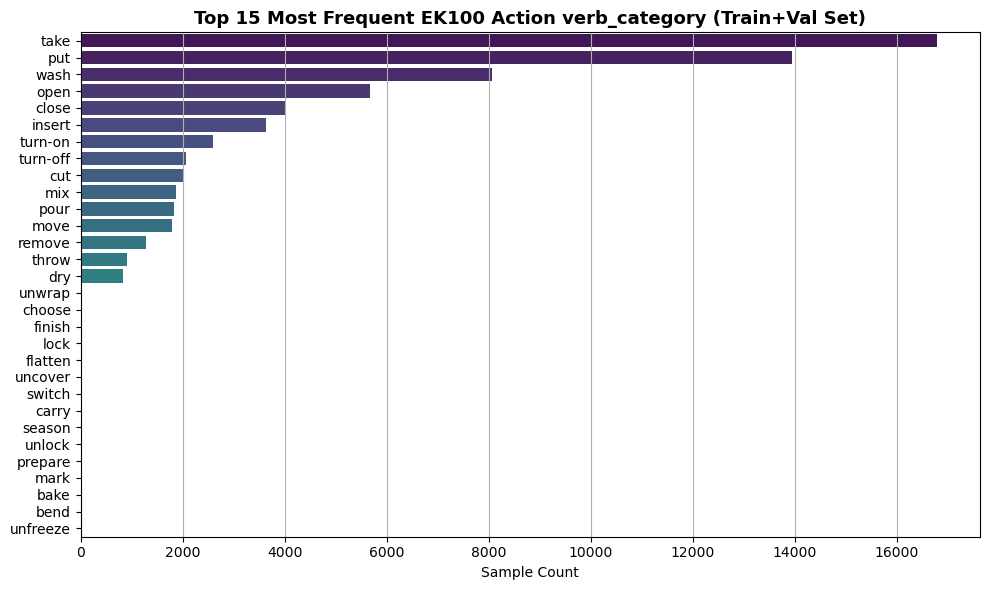

In [36]:
# top 15 and bottom 15 class counts (Train)
train_counts = df['verb_category'].value_counts()

top15 = train_counts.head(15).reset_index()
bottom15 = train_counts.tail(15).reset_index()
top15 = pd.concat([top15, bottom15]).reset_index(drop=True)
top15.columns = ['verb_category', 'count']

fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(zorder=0)
sns.barplot(data=top15, y='verb_category', x='count', palette='viridis', ax=ax)

ax.set_title("Top 15 Most Frequent EK100 Action verb_category (Train+Val Set)", fontsize=13, fontweight='bold')
ax.set_xlabel("Sample Count")
ax.set_ylabel('')  # Clear y-axis label text

plt.tight_layout()
plt.show()

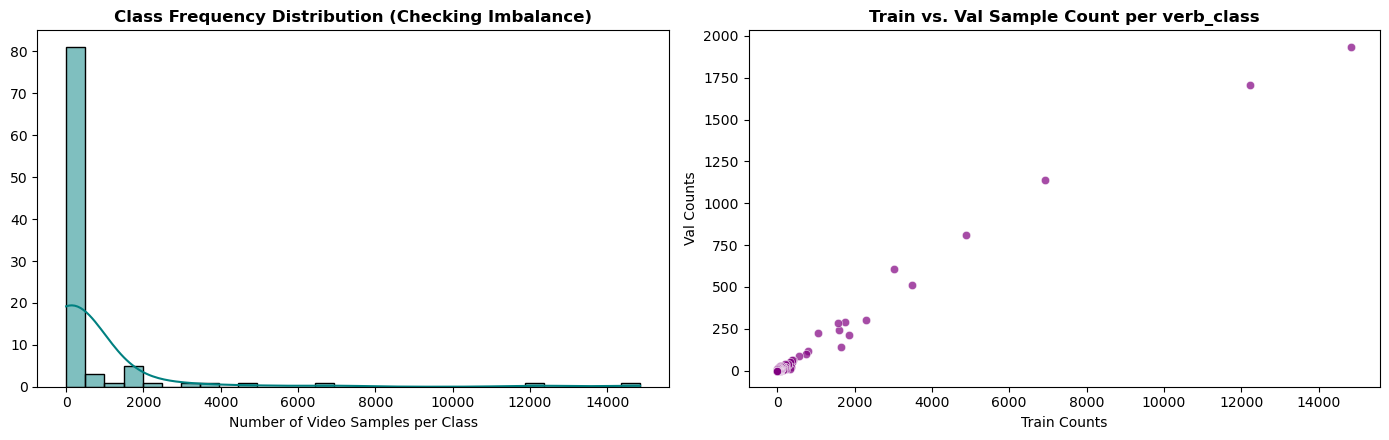

In [37]:
# Group class frequencies by split
class_counts = df.groupby(['verb_class', 'split']).size().reset_index(name='count')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Class frequency distribution curve (Long-tail inspection)
sns.histplot(data=df_train['verb_class'].value_counts(), kde=True, ax=axes[0], color='teal', bins=30)
axes[0].set_title("Class Frequency Distribution (Checking Imbalance)", fontweight='bold')
axes[0].set_xlabel("Number of Video Samples per Class")
axes[0].set_ylabel('')

# Plot 2: Compare train vs val sample counts across classes
sns.scatterplot(
    data=df.groupby('verb_class')['split'].value_counts().unstack().fillna(0),
    x='train', y='val', alpha=0.7, color='purple', ax=axes[1]
)
axes[1].set_title("Train vs. Val Sample Count per verb_class", fontweight='bold')
axes[1].set_xlabel("Train Counts")
axes[1].set_ylabel("Val Counts")

plt.tight_layout()
plt.show()

In [39]:
pd.set_option('display.width', 10000)

df_pairs = df[['narration_id', 'verb_category', 'noun_category', 'split']]
df_pairs.head(2)

,narration_id,verb_category,noun_category,split
0,P01_01_0,open,cupboard,train
1,P01_01_1,turn-on,light,train


In [40]:
df_pairs.columns = ['video_id', 'verb', 'noun', 'split']
df_pairs.head(10)

,video_id,verb,noun,split
0,P01_01_0,open,cupboard,train
1,P01_01_1,turn-on,light,train
2,P01_01_10,open,drawer,train
3,P01_01_100,take,cup,train
4,P01_01_101,open,cupboard,train
5,P01_01_102,insert,cup,train
6,P01_01_103,take,container,train
7,P01_01_104,put,container,train
8,P01_01_105,open,container,train
9,P01_01_106,insert,container,train


In [41]:
print(f"{df_pairs.shape=}")
print(f"{df_pairs.verb.nunique()=}")
print(f"{df_pairs.noun.nunique()=}")

df_pairs.shape=(76885, 4)
df_pairs.verb.nunique()=97
df_pairs.noun.nunique()=293


In [43]:
def compute_cooccurrence_metrics(df_sub):
    """
    Computes:
    -> Raw Counts
    -> Conditional Probability P(Noun | Verb) (what nouns dominate a given action)
    -> PMI (Pointwise Mutual Information) to find unique/strong object-action bindings rather than just frequent generic items.
    """
    total_pairs = len(df_sub)
    
    # Group by (Verb, Noun)
    cooccur = df_sub.groupby(['verb', 'noun']).size().reset_index(name='raw_count')
    cooccur_rev = df_sub.groupby(['noun', 'verb']).size().reset_index(name='raw_count')
    
    # Verb and Noun marginal frequencies
    verb_counts = df_sub['verb'].value_counts().to_dict()
    noun_counts = df_sub['noun'].value_counts().to_dict()
    
    # Compute Conditional Probability: P(Noun | Verb)
    cooccur['p_noun_given_verb'] = cooccur.apply(
        lambda r: r['raw_count'] / verb_counts[r['verb']], axis=1
    )

    cooccur_rev['p_verb_given_noun'] = cooccur_rev.apply(
        lambda r: r['raw_count'] / noun_counts[r['noun']], axis=1
    )

    # Compute Pointwise Mutual Information (PMI)
    # PMI(v, n) = log2( P(v,n) / (P(v) * P(n)) )
    cooccur['pmi'] = cooccur.apply(
        lambda r: np.log2(
            (r['raw_count'] / total_pairs) / 
            ((verb_counts[r['verb']] / total_pairs) * (noun_counts[r['noun']] / total_pairs))
        ), axis=1
    )
    
    return cooccur, cooccur_rev

# Metrics specifically for Direct Objects (Noun 1)
df_noun1 = df_pairs
metrics_noun1, metrics_noun1_rev = compute_cooccurrence_metrics(df_noun1)

In [49]:
# sanity checks
print(metrics_noun1.raw_count.sum())
print(metrics_noun1_rev.raw_count.sum())

76885
76885


# P(Noun|Verb)

In [44]:
# Showing more columns
pd.get_option('display.max_columns')

# Setting the max characters to be displayed
pd.set_option('display.max_colwidth', None)

# display full dataframe pandas / output window widened
pd.set_option('display.width', 10000) # None

In [56]:
print("\n--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Noun|Verb) (what nouns dominate a given action) ---")
print(metrics_noun1[metrics_noun1.raw_count>200].sort_values(by='p_noun_given_verb', ascending=False).head(20))


--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Noun|Verb) (what nouns dominate a given action) ---
          verb      noun  raw_count  p_noun_given_verb       pmi
3488  turn-off       tap       1742           0.840734  4.015433
3524   turn-on       tap       1985           0.764638  3.878561
638        dry      hand        507           0.607914  4.844354
1644      open  cupboard       1569           0.276232  2.988507
321      close  cupboard       1050           0.262697  2.916024
1919      pour     water        419           0.228089  4.408087
1647      open    drawer       1084           0.190845  2.962071
324      close    drawer        733           0.183388  2.904565
510        cut     onion        321           0.157817  3.602399
1390       mix      food        283           0.152069  4.286798
329      close    fridge        604           0.151113  3.005268
1657      open    fridge        794           0.139789  2.892885
3660      wash      hand        854 

# P(Verb|Noun) -- Main interest for object bias

In [57]:
metrics_noun1_rev['full_text'] = "P(" + metrics_noun1_rev['verb'] + "|" + metrics_noun1_rev['noun'] + ") = " + metrics_noun1_rev['p_verb_given_noun'].round(4).astype(str) + ", Count: " + metrics_noun1_rev['raw_count'].astype(str)

In [58]:
# Lets see the second table that is verb given noun but with a raw_count threshold
print("\n--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Verb|Noun) (what verbs dominate a given noun) ---")
print(metrics_noun1_rev[metrics_noun1_rev.raw_count>10].sort_values(by='p_verb_given_noun', ascending=False).head(20))


--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Verb|Noun) (what verbs dominate a given noun) ---
          noun        verb  raw_count  p_verb_given_noun                                  full_text
3674      wall        wash         11           0.916667           P(wash|wall) = 0.9167, Count: 11
515     button       press        118           0.836879       P(press|button) = 0.8369, Count: 118
3535       top        wash        408           0.793774           P(wash|top) = 0.7938, Count: 408
636      chair        move         23           0.793103          P(move|chair) = 0.7931, Count: 23
3136      sink        wash        257           0.758112          P(wash|sink) = 0.7581, Count: 257
2836    recipe        look         38           0.745098         P(look|recipe) = 0.7451, Count: 38
1786      knob        turn         20           0.666667           P(turn|knob) = 0.6667, Count: 20
1794     label      remove         11           0.611111        P(remove|label) = 0

In [ ]:
"""
#### P(verb|noun)
P(press|button) = 0.8369, Count: 118
P(move|chair) = 0.7931, Count: 23
P(wash|sink) = 0.7581, Count: 257
P(look|recipe) = 0.7451, Count: 38
P(turn-on|light) = 0.5882, Count: 60
P(take|napkin) = 0.5568, Count: 98
P(open|cupboard) = 0.5863, Count: 1569
P(open|drawer) = 0.5757, Count: 1084
P(open|fridge) = 0.5487, Count: 794
"""

#### knife and cut

In [61]:
res = metrics_noun1_rev[
    (metrics_noun1_rev['noun'].str.contains('knife')) &
    (metrics_noun1_rev['raw_count']>5)
    ].sort_values(by='p_verb_given_noun', ascending=False)
print(res)

       noun     verb  raw_count  p_verb_given_noun                             full_text
1777  knife     take        909           0.361431    P(take|knife) = 0.3614, Count: 909
1766  knife      put        725           0.288270     P(put|knife) = 0.2883, Count: 725
1781  knife     wash        570           0.226640    P(wash|knife) = 0.2266, Count: 570
1761  knife   insert        107           0.042545  P(insert|knife) = 0.0425, Count: 107
1774  knife  sharpen         48           0.019085  P(sharpen|knife) = 0.0191, Count: 48
1763  knife     move         34           0.013519     P(move|knife) = 0.0135, Count: 34
1759  knife      dry         29           0.011531      P(dry|knife) = 0.0115, Count: 29
1771  knife    scrub         15           0.005964     P(scrub|knife) = 0.006, Count: 15
1767  knife   remove         15           0.005964    P(remove|knife) = 0.006, Count: 15
1770  knife   scrape          9           0.003579    P(scrape|knife) = 0.0036, Count: 9
1756  knife    check 

In [65]:
res = metrics_noun1_rev[
    (metrics_noun1_rev['verb'].str.contains('cut')) &
    (metrics_noun1_rev['raw_count']>30)
    ].sort_values(by='p_verb_given_noun', ascending=False)
print(res)

           noun verb  raw_count  p_verb_given_noun                             full_text
1835       leek  cut         38           0.358491       P(cut|leek) = 0.3585, Count: 38
2274      onion  cut        321           0.321321     P(cut|onion) = 0.3213, Count: 321
966   courgette  cut         70           0.291667  P(cut|courgette) = 0.2917, Count: 70
3480     tomato  cut        152           0.290631    P(cut|tomato) = 0.2906, Count: 152
1867    lettuce  cut         31           0.289720    P(cut|lettuce) = 0.2897, Count: 31
711      chilli  cut         54           0.285714     P(cut|chilli) = 0.2857, Count: 54
1022   cucumber  cut         59           0.255411   P(cut|cucumber) = 0.2554, Count: 59
2242      olive  cut         45           0.248619      P(cut|olive) = 0.2486, Count: 45
588      carrot  cut        114           0.239496    P(cut|carrot) = 0.2395, Count: 114
2740     potato  cut        157           0.238965     P(cut|potato) = 0.239, Count: 157
1422     garlic  cut 

### watch some videos for these action classes

In [68]:
df = df[['narration_id', 'narration','verb','verb_class','verb_category' , 'noun','noun_class','noun_category']]
df.head(3)

,narration_id,narration,verb,verb_class,verb_category,noun,noun_class,noun_category
0,P01_01_0,open door,open,3,open,door,3,cupboard
1,P01_01_1,turn on light,turn-on,6,turn-on,light,114,light
2,P01_01_10,open drawer,open,3,open,drawer,8,drawer


In [71]:
"""
#### P(verb|noun)
P(press|button) = 0.8369, Count: 118
P(move|chair) = 0.7931, Count: 23
P(wash|sink) = 0.7581, Count: 257
P(look|recipe) = 0.7451, Count: 38
P(turn-on|light) = 0.5882, Count: 60
P(take|napkin) = 0.5568, Count: 98
P(open|cupboard) = 0.5863, Count: 1569
P(open|drawer) = 0.5757, Count: 1084
P(open|fridge) = 0.5487, Count: 794
"""

templates = [
    "press",
    "move",
    "wash",
    "look",
    "turn-on",
    "take",
    "open",
]

sampled_df = pd.DataFrame()
## run a forloop over templates and for each template, sample 2 rows from df and append into sampled_df
for template in templates:
    df_temp = df[df['verb_category'] == template]
    
    sampled_rows = df_temp.sample(n=3, random_state=42)
    sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)  

    if template=='press':
        sampled_rows = df_temp[df_temp['noun_category'] == 'button'].sample(n=3, random_state=42)
        sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)
    elif template=='move':
        sampled_rows = df_temp[df_temp['noun_category'] == 'chair'].sample(n=3, random_state=42)
        sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)
    elif template=='wash':
        sampled_rows = df_temp[df_temp['noun_category'] == 'sink'].sample(n=3, random_state=42)
        sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)
    elif template=='look':
        sampled_rows = df_temp[df_temp['noun_category'] == 'recipe'].sample(n=3, random_state=42)
        sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)
    elif template=='turn-on':
        sampled_rows = df_temp[df_temp['noun_category'] == 'light'].sample(n=3, random_state=42)
        sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)
    elif template=='take':
        sampled_rows = df_temp[df_temp['noun_category'] == 'napkin'].sample(n=3, random_state=42)
        sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)
    elif template=='open':
        sampled_rows = df_temp[df_temp['noun_category'] == 'cupboard'].sample(n=3, random_state=42)
        sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)

        sampled_rows = df_temp[df_temp['noun_category'] == 'drawer'].sample(n=3, random_state=42)
        sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)
    
        sampled_rows = df_temp[df_temp['noun_category'] == 'fridge'].sample(n=3, random_state=42)
        sampled_df = pd.concat([sampled_df, sampled_rows], ignore_index=True)
    
sampled_df

,narration_id,narration,verb,verb_class,verb_category,noun,noun_class,noun_category
0,P07_04_72,press button,press,21,press,button,92,button
1,P02_108_387,press button,press,21,press,button,92,button
2,P02_101_54,press button,press,21,press,button,92,button
3,P04_104_168,press button on scales,press,21,press,button,92,button
4,P07_04_71,press button,press,21,press,button,92,button
5,P02_01_7,press button,press,21,press,button,92,button
6,P22_14_250,move bottle,move,11,move,bottle,15,bottle
7,P02_118_20,move bag,move,11,move,bag,19,bag
8,P28_16_49,move piece of pepper,move,11,move,piece:pepper,37,pepper
9,P35_108_61,move chair,move,11,move,chair,182,chair


In [72]:
ek100_path

PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/epic_kitchens_100_annotations')

In [74]:
# Ensure destination directory exists
os.makedirs('./specific_action_clips_ek100', exist_ok=True)

for _, row in sampled_df.iterrows():
    src = f"/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/epic_kitchens_100/clips/{row['narration_id']}.mp4"
    dst = f"./specific_action_clips_ek100/{row['verb_category']}_{row['noun_category']}_{row['narration_id']}.mp4"
    os.system(f"cp '{src}' '{dst}'")